# Reading and running this notebook

Part 1 of 3: project introduction, setup, exploratory analysis, and Section A. Run top to bottom in Google Colab with the original transaction CSV. Original code and saved outputs are preserved. Continue reading with 02_section_B.ipynb, then 03_section_C.ipynb. Each subsequent notebook includes its own unchanged prerequisite cells because separate Colab notebooks do not share Python variables.

Stories Coffee: Does the same menu fit every branch?

The problem

Stories sells the same 45 products across Harbour, Garden, and Uptown. However, the branches differ in sales volume, product sales mix, and recorded costs.

Harbour sells approximately 144 units per day, Garden 98, and Uptown 56. These are product units, not customer orders.

After adjusting for branch volume, sandwiches represent a 41% higher share of units sold at Uptown than across the chain. Desserts represent a 19% lower share at Uptown and a 26% higher share at Garden. These patterns describe recorded purchases, which may also reflect product availability and promotions.

For the same products, Garden’s recorded unit costs are approximately 43% higher than Harbour’s and 49% higher than Uptown’s. Garden’s recorded gross margin is approximately 47%, compared with 65% at Harbour and 63% at Uptown. These are gross margins before unrecorded waste and operating expenses.

Slow sales can create waste exposure when perishable products are prepared in advance. Soup of the Day, for example, sells approximately three bowls per week at Uptown. However, the dataset does not record preparation quantities or disposals, so it cannot establish whether soup is wasted or what that waste costs.

Harbour tested 15% discounts on Cold Coffee and Desserts during March 12–19 and May 12–19, 2026. At the pre-promotion product mix, sales needed to rise approximately 28% to preserve gross profit.

Using the combined trends at Garden and Uptown as a comparison, estimated unit sales were approximately 8% above the no-promotion benchmark in March and 6% below it in May. May’s estimated gross-profit shortfall was approximately USD 332 for the two promoted categories.

March’s financial result is inconclusive: depending on the comparison branch, the estimated gross-profit difference ranges from a shortfall of USD 234 to a gain of USD 41. Placebo checks show that branch trends can diverge without the promotion, so these estimates do not prove causation.

The questions we answer

Which products sell slowly at each branch, and how much of that pattern reflects branch volume versus differences in sales mix?

How much additional waste would eliminate those products’ recorded gross profit?

Do low-profit products such as water and espresso appear alongside other profitable items in baskets?

Did Harbour’s discounts generate enough additional sales to preserve gross profit?

How large is Garden’s matched-product cost premium, and what evidence is needed to explain it?

Can product characteristics help predict sales for an unseen product, and how should Stories test changes before acting?

How we answer them

Section A checks data quality, documents product tags, and compares sales mix across branches.

Section B measures slow-perishable exposure, examines water and espresso baskets, evaluates Harbour’s promotions, and estimates Garden’s cost difference while holding its sales mix constant.

Section C compares prediction models with simple baselines, estimates pilot sensitivity, proposes practical tests, and separates measured findings from assumptions.

What the project can establish

The analysis identifies financial concerns and priorities for investigation. It does not prove that the identical menu causes those concerns.

Waste thresholds are hypothetical scenarios. Garden’s cost differences are benchmarks, not guaranteed savings. Promotion estimates depend on comparison assumptions. These figures must not be added together as one total loss.

Team: Houssein Karnib · Omar El Hajj · Sami Marouni

# ***Setup and Exploratory Data Analysis***

In [90]:
import os
import pandas as pd

FILE = "stories_transactions.csv"

# Upload the CSV if it isn't in Colab's file panel yet
if not os.path.exists(FILE):
    from google.colab import files
    uploaded = files.upload()                  # pick your CSV
    os.rename(next(iter(uploaded)), FILE)      # keep the name the rest of the code expects

# Load the data
df = pd.read_csv(FILE)
print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")

#Customer ID dropped after the randomness test
df = df.drop(columns=["Customer ID"])
print(f"After dropping Customer ID: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Loaded 51,177 rows x 14 columns
After dropping Customer ID: 51,177 rows x 13 columns


,Transaction ID,Date,Time,Branch,Order Type,Product,Category,Quantity,Unit Price (USD),Discount Rate,Unit Cost (USD),Line Revenue (USD),Line Gross Profit (USD)
0,SYN-0000001,2026-01-01,22:37:35,Harbour,Takeaway,Fresh Orange Juice,Cold Drinks,1,6.04,0.0,2.12,6.04,3.92
1,SYN-0000002,2026-01-01,17:34:07,Garden,Dine-in,Egg Sandwich,Breakfast,1,8.15,0.0,4.45,8.15,3.70
2,SYN-0000003,2026-01-01,22:45:29,Harbour,Dine-in,Brownie,Desserts,1,5.41,0.0,2.37,5.41,3.04
3,SYN-0000004,2026-01-01,21:36:38,Uptown,Dine-in,Iced Mocha,Cold Coffee,1,6.00,0.0,2.14,6.00,3.86
4,SYN-0000005,2026-01-01,12:34:01,Harbour,Dine-in,Classic Matcha,Matcha & Tea,1,6.77,0.0,2.27,6.77,4.50


In [91]:
import sys

import numpy as np
import pandas as pd

ID_COL = "Customer ID"
TXN_COLS = ["Date", "Time", "Branch", "Order Type"]  # same on every line of a transaction
NUM_COLS = ["Quantity", "Unit Price (USD)", "Discount Rate", "Unit Cost (USD)",
            "Line Revenue (USD)", "Line Gross Profit (USD)"]
CAT_COLS = ["Branch", "Order Type", "Product", "Category"]


def load(path="stories_transactions.csv"):
    """Load the CSV and drop Customer ID."""
    df = pd.read_csv(path)
    print(f"Loaded {df.shape[0]:,} rows x {df.shape[1]} columns")
    if ID_COL in df.columns:
        n = df[ID_COL].isna().sum()
        print(f"{ID_COL}: {n:,} missing ({n / len(df):.1%}) -> dropping column")
        # Optional: keep the signal before dropping (registered customer vs. walk-in)
        # df["Has Customer ID"] = df[ID_COL].notna().astype(int)
        df = df.drop(columns=[ID_COL])
    return df


In [92]:
def summarize(df):
    """Print missing values and feature distributions."""
    print("\n=== Missing values ===")
    miss = df.isna().sum()
    table = pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(2)})
    print(table.sort_values("missing", ascending=False).to_string())

    print("\n=== Numeric distributions ===")
    num = df[[c for c in NUM_COLS if c in df.columns]]
    desc = num.describe().T
    desc["median"] = num.median()
    desc["skew"] = num.skew()
    q1, q3 = num.quantile(0.25), num.quantile(0.75)
    iqr = q3 - q1
    desc["iqr_outliers"] = ((num < q1 - 1.5 * iqr) | (num > q3 + 1.5 * iqr)).sum()
    print(desc.round(3).to_string())

    print("\n=== Categorical distributions ===")
    for c in [c for c in CAT_COLS if c in df.columns]:
        vc = df[c].value_counts()
        print(f"\n{c}: {df[c].nunique()} unique, mode = {vc.index[0]}")
        print(pd.DataFrame({"count": vc, "pct": (vc / len(df) * 100).round(1)}).head(10).to_string())

    print("\n=== Other checks ===")
    print("Exact duplicate rows:", df.duplicated().sum())
    print("Unique transactions:", df["Transaction ID"].nunique(), "(rows are line items)")
    print("Date range:", df["Date"].min(), "to", df["Date"].max())
    print("Discount rates used:", sorted(df["Discount Rate"].dropna().unique().tolist()))

In [93]:
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE, BLUE = "#e1e0d9", "#c3c2b7", "#2a78d6"
DAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]


def _compact(x, _=None):
    return f"{x / 1000:g}K" if abs(x) >= 1000 else f"{x:g}"


def _style(ax, title, subtitle, horizontal=False):
    """Quiet chrome: hairline grid on the value axis, one baseline, muted ticks."""
    from matplotlib.ticker import FuncFormatter
    ax.set_facecolor(SURFACE)
    for side in ax.spines:
        ax.spines[side].set_visible(False)
    base = "left" if horizontal else "bottom"
    ax.spines[base].set_visible(True)
    ax.spines[base].set_color(BASELINE)
    ax.spines[base].set_linewidth(0.8)
    ax.tick_params(colors=MUTED, labelsize=8, length=0, pad=4)
    ax.grid(axis="x" if horizontal else "y", color=GRID, linewidth=0.5)
    ax.set_axisbelow(True)
    (ax.xaxis if horizontal else ax.yaxis).set_major_formatter(FuncFormatter(_compact))
    ax.set_title(title, loc="left", fontsize=11, fontweight="semibold", color=INK, pad=20)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=8, color=INK_2, va="bottom")


def _thickness(ax, n, horizontal=False, max_px=36):
    """Bar thickness as a fraction of its slot, capped at ~24 screen px (36 px at 150 dpi)."""
    fig, box = ax.figure, ax.get_position()
    span_in = box.height * fig.get_figheight() if horizontal else box.width * fig.get_figwidth()
    return min(0.7, max_px / (span_in * fig.dpi / n))

In [94]:
def _label(ax, x, y, text, horizontal=False):
    off = (4, 0) if horizontal else (0, 3)
    ax.annotate(text, (y, x) if horizontal else (x, y), xytext=off, textcoords="offset points",
                ha="left" if horizontal else "center", va="center" if horizontal else "bottom",
                fontsize=8, color=INK)

In [95]:
def _bars(ax, labels, counts, n, title, subtitle, horizontal=False, label_all=True):
    pos = np.arange(len(counts))
    w = _thickness(ax, len(counts), horizontal)
    if horizontal:
        ax.barh(pos, counts, height=w, color=BLUE)
        ax.set_yticks(pos, labels)
        ax.invert_yaxis()
        ax.set_xlim(0, max(counts) * 1.18)
    else:
        ax.bar(pos, counts, width=w, color=BLUE)
        ax.set_xticks(pos, labels)
        ax.set_ylim(0, max(counts) * 1.18)
    if label_all:
        for p, c in zip(pos, counts):
            _label(ax, p, c, f"{c / n:.1%}", horizontal)
    _style(ax, title, subtitle, horizontal)

In [96]:
def plot_distributions(df, save_prefix=None):
    """One panel per feature. Returns (numeric_fig, categorical_fig); saves PNGs if save_prefix."""
    import matplotlib.pyplot as plt
    import matplotlib.dates as mdates
    from matplotlib import font_manager

    installed = {f.name for f in font_manager.fontManager.ttflist}
    family = next((f for f in ["Inter", "Segoe UI", "Helvetica Neue", "Arial"] if f in installed),
                  "DejaVu Sans")
    n = len(df)
    miss = df.isna().sum()

    with plt.rc_context({"font.family": family, "figure.dpi": 150}):
        # ---- Figure 1: numeric features
        fig1, axes = plt.subplots(2, 3, figsize=(15, 8.8), facecolor=SURFACE)
        fig1.subplots_adjust(left=0.05, right=0.98, top=0.83, bottom=0.07, wspace=0.2, hspace=0.75)
        fig1.text(0.05, 0.955, "Numeric feature distributions", fontsize=16,
                  fontweight="semibold", color=INK)
        fig1.text(0.05, 0.925, f"{n:,} rows (line items) after dropping Customer ID  ·  "
                  f"{int(miss.sum())} missing values in total", fontsize=9.5, color=INK_2)

        bin_width = {"Unit Price (USD)": 0.25, "Unit Cost (USD)": 0.2,
                     "Line Revenue (USD)": 0.5, "Line Gross Profit (USD)": 0.25}
        for ax, (col, bw) in zip(axes.flat, bin_width.items()):
            s = df[col].dropna()
            edges = np.arange(np.floor(s.min() / bw) * bw, s.max() + bw, bw)
            counts, _, _ = ax.hist(s, bins=edges, color=BLUE, edgecolor=SURFACE, linewidth=1)
            ax.set_ylim(0, counts.max() * 1.18)
            med = s.median()
            ax.axvline(med, color=INK, linewidth=1.1)
            ax.text(med, 0.97, f"  median {med:.2f}", transform=ax.get_xaxis_transform(),
                    fontsize=8, color=INK, va="top")
            _style(ax, col, f"mean {s.mean():.2f}  ·  skew {s.skew():.2f}  ·  "
                            f"{miss[col]} missing")

        q = df["Quantity"].value_counts().sort_index()
        _bars(axes.flat[4], [f"{v:g}" for v in q.index], q.values, n, "Quantity",
              f"{miss['Quantity']} missing  ·  share of rows")
        d = df["Discount Rate"].value_counts().sort_index()
        _bars(axes.flat[5], [f"{v:.0%}" for v in d.index], d.values, n, "Discount Rate",
              f"{miss['Discount Rate']} missing  ·  share of rows")

        # ---- Figure 2: categorical and time features
        fig2 = plt.figure(figsize=(15, 13), facecolor=SURFACE)
        gs = fig2.add_gridspec(3, 3, left=0.115, right=0.98, top=0.885, bottom=0.05,
                               wspace=0.32, hspace=0.62)
        fig2.text(0.05, 0.955, "Categorical and time feature distributions", fontsize=16,
                  fontweight="semibold", color=INK)
        fig2.text(0.05, 0.935, f"{n:,} rows (line items)  ·  counts are rows  ·  "
                  f"{int(miss.sum())} missing values in total", fontsize=9.5, color=INK_2)

        for cell, col in [(gs[0, 0], "Branch"), (gs[0, 1], "Order Type")]:
            vc = df[col].value_counts()
            _bars(fig2.add_subplot(cell), vc.index.tolist(), vc.values, n, col,
                  f"{df[col].nunique()} values  ·  {miss[col]} missing")

        dates = pd.to_datetime(df["Date"], errors="coerce")
        dow = dates.dt.day_name().value_counts().reindex(DAYS, fill_value=0)
        ax = fig2.add_subplot(gs[0, 2])
        _bars(ax, [x[:3] for x in DAYS], dow.values, n, "Day of week (from Date)",
              "share of rows; busiest day labeled", label_all=False)
        top = int(dow.values.argmax())
        _label(ax, top, dow.values[top], f"{DAYS[top][:3]} {dow.values[top] / n:.1%}")

        vc = df["Category"].value_counts()
        _bars(fig2.add_subplot(gs[1, 0]), vc.index.tolist(), vc.values, n, "Category",
              f"{df['Category'].nunique()} values  ·  {miss['Category']} missing", horizontal=True)

        hours = pd.to_datetime(df["Time"], format="%H:%M:%S", errors="coerce").dt.hour
        hc = hours.value_counts().sort_index()
        ax = fig2.add_subplot(gs[1, 1:])
        _bars(ax, [f"{h:g}" for h in hc.index], hc.values, n, "Hour of day (from Time)",
              f"{miss['Time']} missing  ·  busiest hour labeled", label_all=False)
        top = int(hc.values.argmax())
        _label(ax, top, hc.values[top], f"{hc.index[top]:g}:00  {hc.values[top] / n:.1%}")

        vc = df["Product"].value_counts()
        ax = fig2.add_subplot(gs[2, 0])
        _bars(ax, vc.index[:15].tolist(), vc.values[:15], n, "Product (top 15)",
              f"{len(vc)} values; the other {len(vc) - 15} hold "
              f"{vc.values[15:].sum() / n:.0%} of rows  ·  {miss['Product']} missing",
              horizontal=True, label_all=False)

        per_day = dates.value_counts().sort_index()
        ax = fig2.add_subplot(gs[2, 1:])
        ax.plot(per_day.index, per_day.values, color=BLUE, linewidth=1.4,
                solid_joinstyle="round", solid_capstyle="round")
        ax.set_ylim(0, per_day.max() * 1.12)
        ax.xaxis.set_major_locator(mdates.MonthLocator())
        ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
        _style(ax, "Rows per day (Date)", f"{per_day.index.min():%d %b} to "
               f"{per_day.index.max():%d %b %Y}  ·  {miss['Date']} missing")

        if save_prefix:
            fig1.savefig(f"{save_prefix}_numeric.png", dpi=150, facecolor=SURFACE)
            fig2.savefig(f"{save_prefix}_categorical.png", dpi=150, facecolor=SURFACE)
    return fig1, fig2

Loaded 51,177 rows x 14 columns
Customer ID: 18,691 missing (36.5%) -> dropping column

=== Missing values ===
                         missing  pct
Transaction ID                 0  0.0
Date                           0  0.0
Time                           0  0.0
Branch                         0  0.0
Order Type                     0  0.0
Product                        0  0.0
Category                       0  0.0
Quantity                       0  0.0
Unit Price (USD)               0  0.0
Discount Rate                  0  0.0
Unit Cost (USD)                0  0.0
Line Revenue (USD)             0  0.0
Line Gross Profit (USD)        0  0.0

=== Numeric distributions ===
                           count   mean    std   min   25%   50%   75%    max  median   skew  iqr_outliers
Quantity                 51177.0  1.057  0.232  1.00  1.00  1.00  1.00   2.00    1.00  3.827          2910
Unit Price (USD)         51177.0  5.692  2.169  1.87  4.08  5.41  6.77  13.07    5.41  0.955          1457
Disco

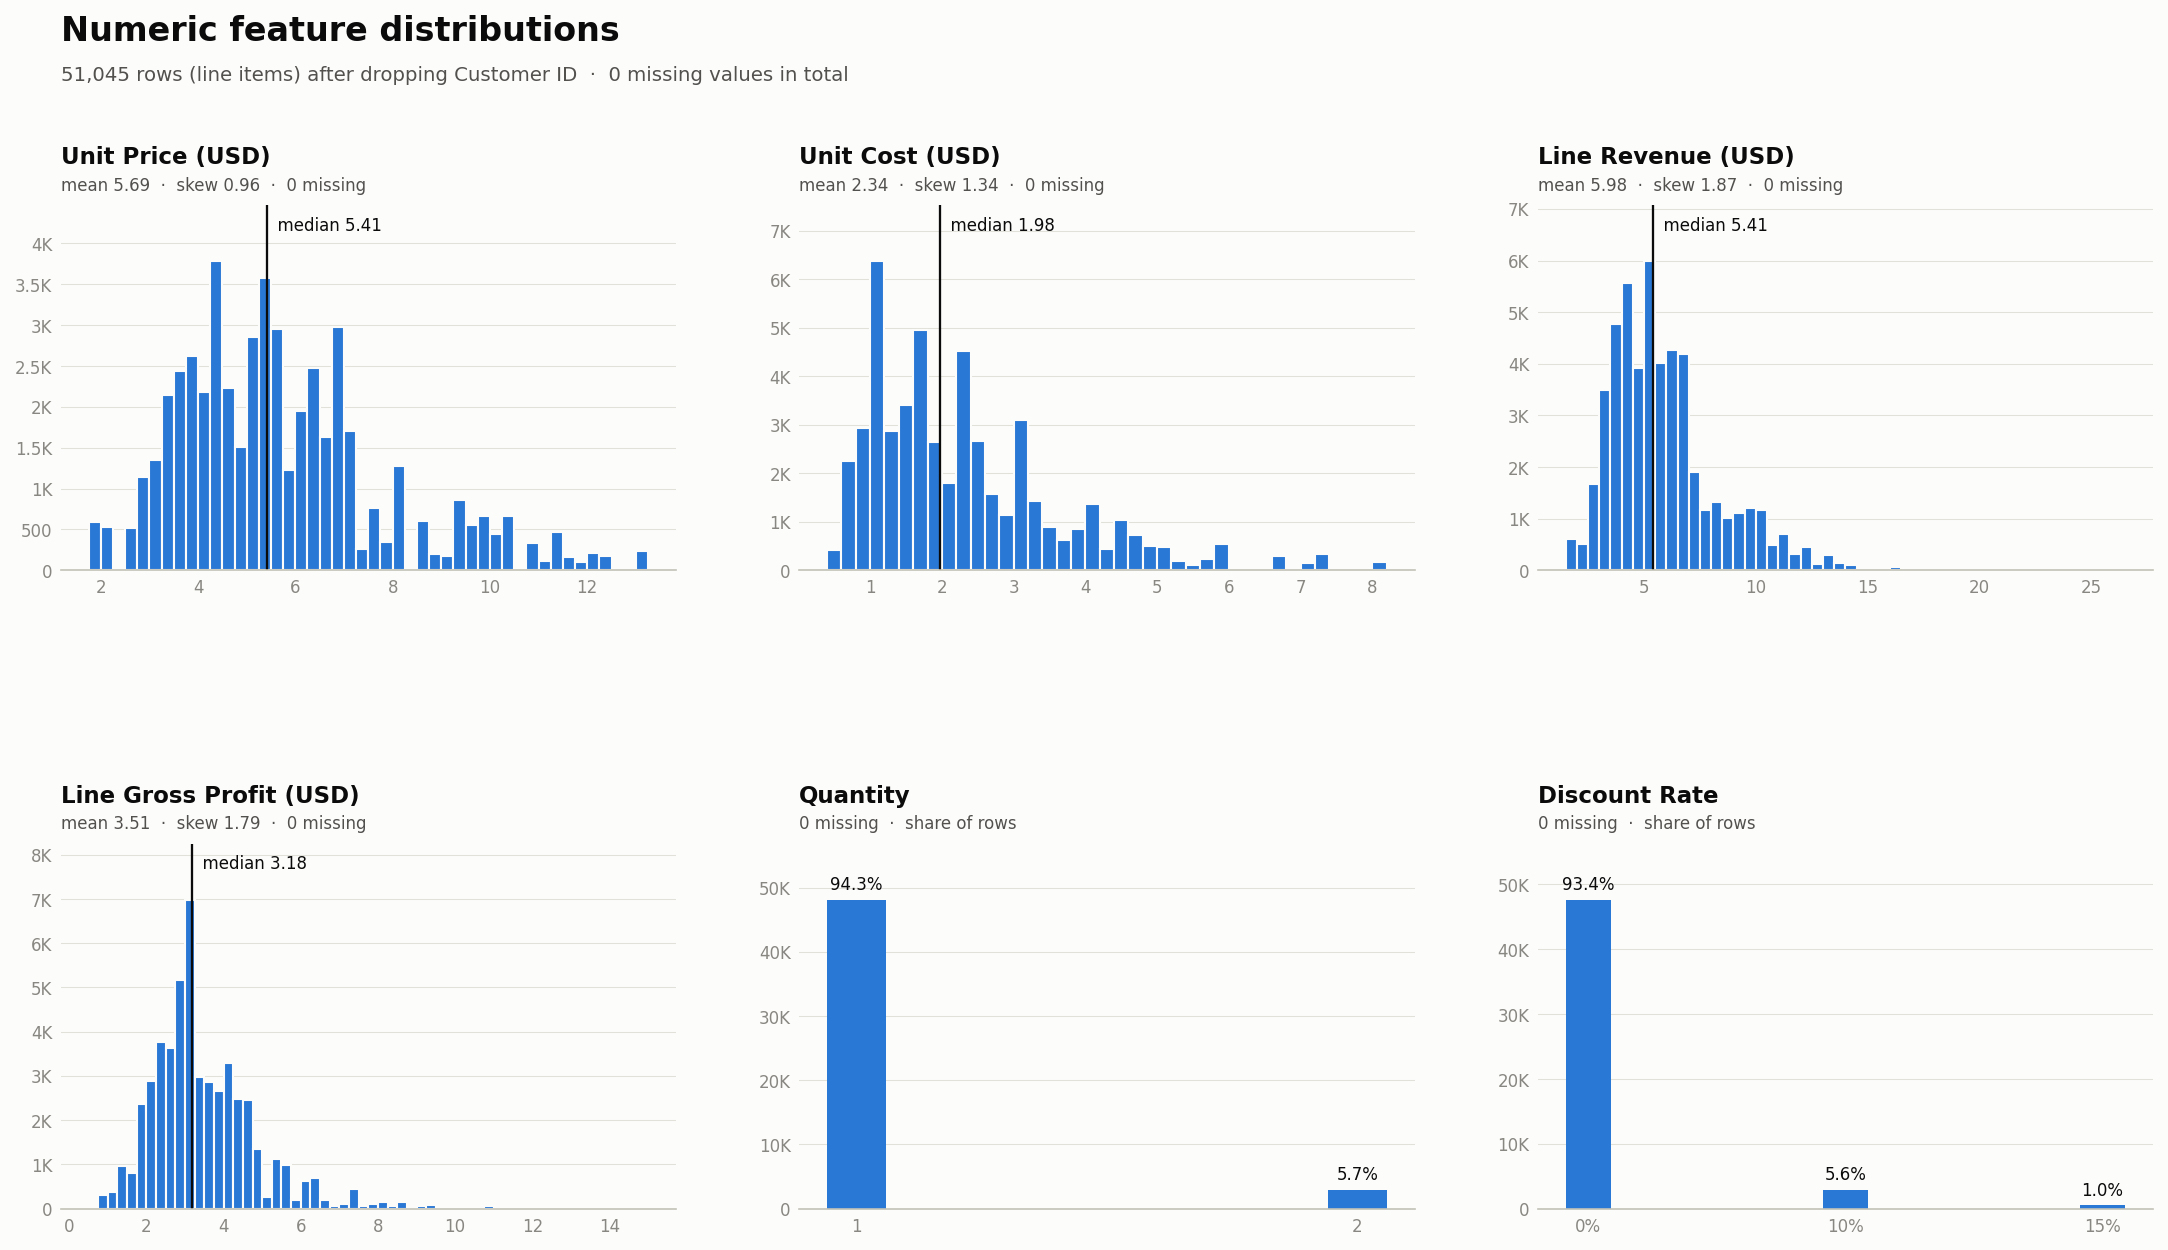

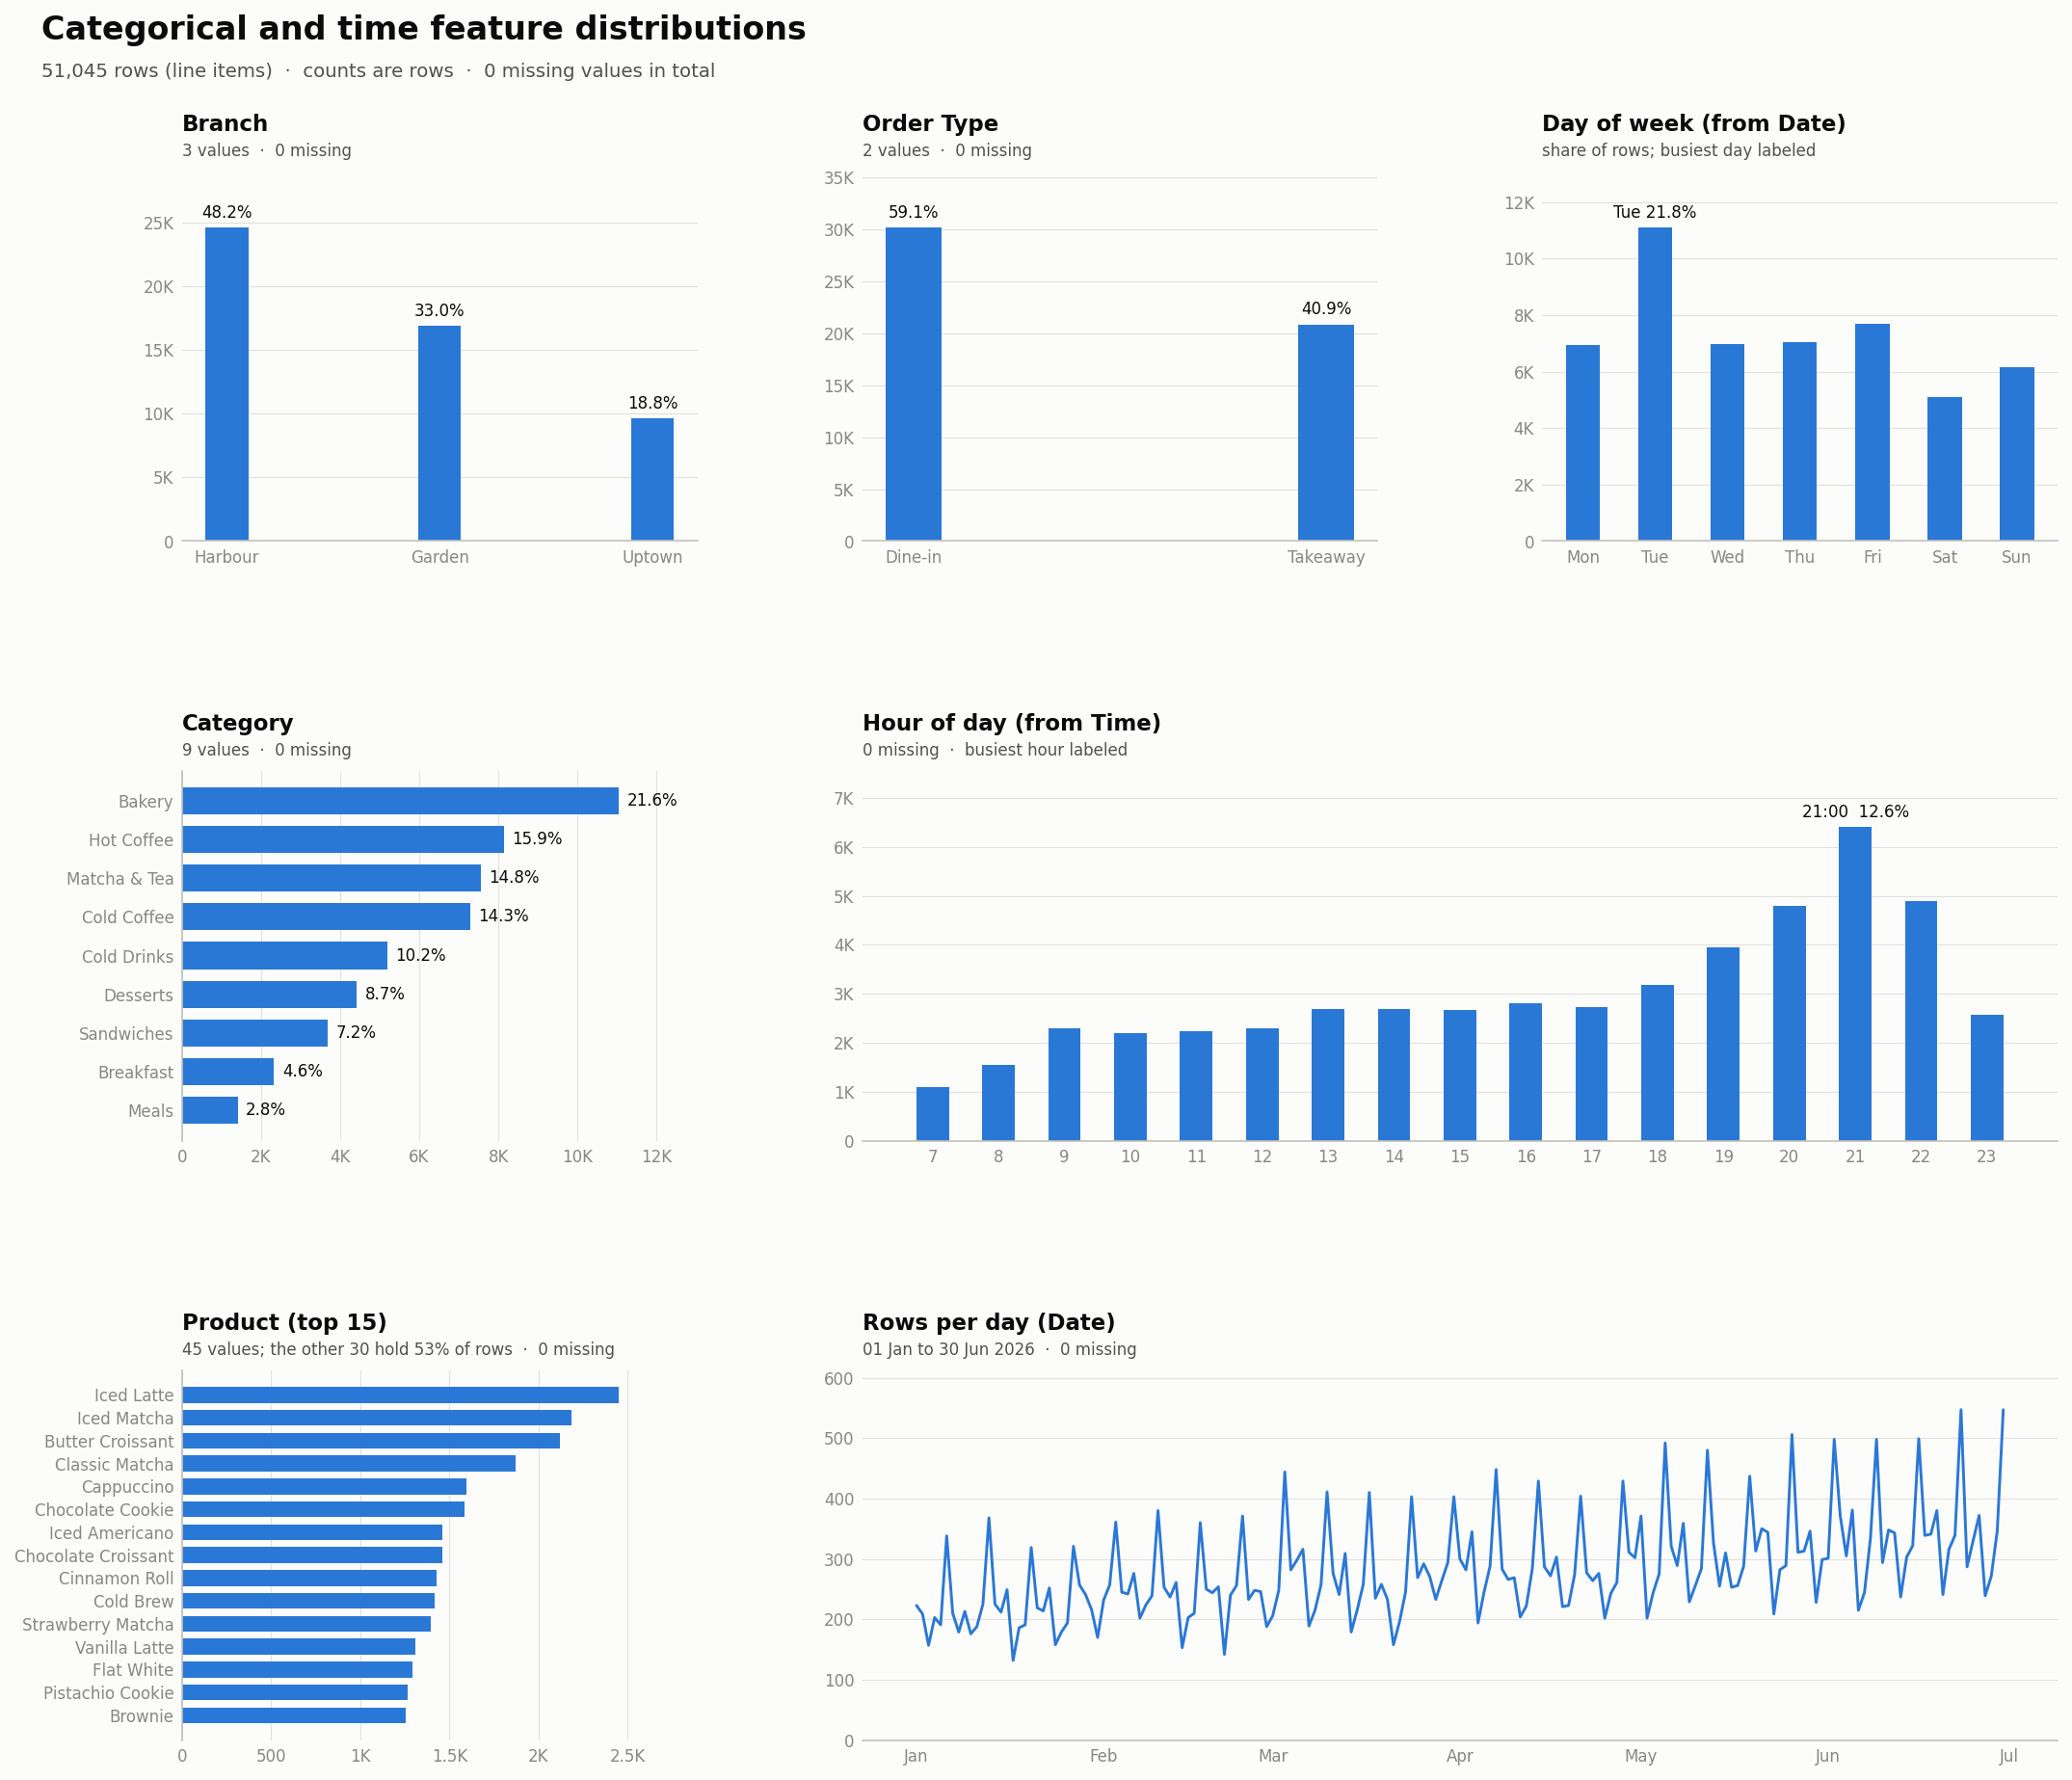

In [97]:
if __name__ == "__main__":
    csv_args = [a for a in sys.argv[1:] if a.lower().endswith(".csv")]
    path = csv_args[0] if csv_args else "stories_transactions.csv"
    data = load(path)
    summarize(data)
    data = data.drop_duplicates()                     # remove the 132 duplicate lines
    print(f"\nAfter dropping duplicates: {len(data):,} rows")
    data.to_csv("stories_transactions_clean.csv", index=False)
    print("Saved stories_transactions_clean.csv")
    try:
        plot_distributions(data, save_prefix="distributions")
        print("Saved distributions_numeric.png and distributions_categorical.png")
    except ImportError:
        print("pip install matplotlib to also save the distribution charts")

In [98]:
# Optional: download the cleaned dataset for sharing with the team.
from google.colab import files
files.download("stories_transactions_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

EDA notes. No missing values except Customer ID (36.5% of rows), so no imputation was needed. The summary statistics are computed before removing 132 identical duplicate lines (0.26% of rows, treated as double entries); the saved clean file has 51,045 rows. IQR flags 1,450–3,400 rows per numeric column, but none are errors: the flagged quantities are orders of 2, the flagged discounts are the 10% and 15% discounts, and the flagged prices, costs and revenues belong to the most expensive items (the bowls and the Chicken Pesto Sandwich). We keep all rows. Volume grows 52–60% from January to June at all three branches, and Tuesdays run about 1.5× other days.

# Section A: Data quality and characteristics


Product tags — definitions and limitations

The product tags were manually assigned by the team. They are working classifications, not verified ingredient lists, recipes, or storage requirements.

Temperature describes the assumed serving temperature: hot, cold, or ambient.

Type distinguishes food from drinks.

Sweet and caffeine indicate the team’s assumed sweetness and caffeine classifications. They require recipe confirmation.

The milk flag is not a complete dairy-ingredient indicator. For example, Halloumi Wrap and Butter Croissant are coded 0, while Granola Yoghurt and milk-based drinks are coded 1. It must not be interpreted as identifying dairy-free products. Until the team confirms a consistent definition, comparisons and predictions involving this flag remain provisional.

The perishable flag identifies the 23 products selected for the slow-perishable analysis. It is not a complete inventory spoilage classification. Milk-based drinks are coded 0 even though their ingredients can spoil, while Frozen Yoghurt Cup is coded 1 even though its usable storage period may differ from fresh food.

A perishable value of 1 does not mean that an unsold product is discarded daily. Preparation methods, storage conditions, shelf life, and actual disposals are unavailable.

Price tier divides products into three groups using their average recorded list prices. It describes relative prices in this dataset, not an external market classification.

Category comes from the transaction data.

Before operational use, the team should validate these definitions against recipes and preparation practices. Any changes to tag values require rerunning the characteristic comparisons, the slow-perishable analysis, and the prediction model. Reported results currently apply to the original tags.

In [99]:
# ===== Section A: data quality checks =====
import numpy as np, pandas as pd
raw = pd.read_csv("stories_transactions.csv")          # reload WITH Customer ID for the test below

# 1) Duplicates: count, then drop (assumption: identical lines are double entries)
print("Exact duplicate lines:", raw.duplicated().sum())
raw = raw.drop_duplicates().reset_index(drop=True)
print("Rows after dropping duplicates:", len(raw))

# 2) Missing values: only Customer ID has any
print(raw.isna().sum()[raw.isna().sum() > 0])

# 3) Arithmetic: revenue and gross profit follow the formulas on every row
rev = (raw["Quantity"] * raw["Unit Price (USD)"] * (1 - raw["Discount Rate"])).round(2)
gp  = (raw["Line Revenue (USD)"] - raw["Quantity"] * raw["Unit Cost (USD)"]).round(2)
print("Revenue mismatches:", (abs(rev - raw["Line Revenue (USD)"]) > 0.011).sum(),
      "| Gross profit mismatches:", (abs(gp - raw["Line Gross Profit (USD)"]) > 0.011).sum())

# 4) One fixed price and cost per product per branch, all six months
n = raw.groupby(["Product", "Branch"])[["Unit Price (USD)", "Unit Cost (USD)"]].nunique()
print("Product-branch pairs with more than one price or cost:", int((n > 1).any(axis=1).sum()), "of", len(n))
cost = raw.groupby(["Product", "Branch"])["Unit Cost (USD)"].first().unstack()
ratio = cost["Garden"] / cost["Harbour"]
print(f"Garden cost / Harbour cost: min {ratio.min():.3f}, max {ratio.max():.3f} (every product)")
m = raw.groupby("Branch")[["Line Gross Profit (USD)", "Line Revenue (USD)"]].sum()
print("Gross margin by branch:", (m.iloc[:, 0] / m.iloc[:, 1]).round(3).to_dict())

# 5) Customer IDs: does a customer behave consistently? Compare with randomly shuffled IDs
rng = np.random.default_rng(0)
def top_share(d, col, min_n):
    s = d.groupby("Customer ID")[col].agg(lambda x: x.value_counts().iloc[0] / len(x))
    k = d.groupby("Customer ID").size()
    return s[k >= min_n].mean()
tx = raw.drop_duplicates("Transaction ID").dropna(subset=["Customer ID"])
ln = raw.dropna(subset=["Customer ID"])
for name, d, col, k in [("favorite branch", tx, "Branch", 5), ("favorite product", ln, "Product", 8)]:
    real = top_share(d, col, k)
    fake = np.mean([top_share(d.assign(**{col: rng.permutation(d[col].values)}), col, k) for _ in range(10)])
    print(f"Share of visits to {name}: real customers {real:.3f} vs shuffled IDs {fake:.3f}")
print(
    "Customer-ID checks: the observed average favourite-branch and "
    "favourite-product shares are similar to the averages from ten "
    "shuffled comparisons. These limited checks do not prove that IDs "
    "are random or unusable. We exclude Customer ID from the working "
    "analysis pending validation of its meaning and reliability."
)
df = raw.drop(columns=["Customer ID"])

# ===== Product characteristics (assumption: our own tagging) =====
T = {  # product: (temperature, food_or_drink, milk, sweet, caffeine, perishable)
 "Almond Croissant":("ambient","food",0,1,0,1), "Banana Bread":("ambient","food",0,1,0,1),
 "Blueberry Muffin":("ambient","food",0,1,0,1), "Butter Croissant":("ambient","food",0,0,0,1),
 "Chocolate Cookie":("ambient","food",0,1,0,1), "Chocolate Croissant":("ambient","food",0,1,0,1),
 "Cinnamon Roll":("ambient","food",0,1,0,1), "Pistachio Cookie":("ambient","food",0,1,0,1),
 "Avocado Toast":("hot","food",0,0,0,1), "Egg Sandwich":("hot","food",0,0,0,1),
 "Granola Yoghurt":("cold","food",1,1,0,1), "Coffee Frappe":("cold","drink",1,1,1,0),
 "Cold Brew":("cold","drink",0,0,1,0), "Iced Americano":("cold","drink",0,0,1,0),
 "Iced Latte":("cold","drink",1,0,1,0), "Iced Mocha":("cold","drink",1,1,1,0),
 "Fresh Orange Juice":("cold","drink",0,1,0,1), "Lemonade":("cold","drink",0,1,0,0),
 "Peach Iced Tea":("cold","drink",0,1,1,0), "Sparkling Water":("cold","drink",0,0,0,0),
 "Still Water":("cold","drink",0,0,0,0), "Brownie":("ambient","food",0,1,0,1),
 "Cheesecake Slice":("cold","food",1,1,0,1), "Frozen Yoghurt Cup":("cold","food",1,1,0,1),
 "Tiramisu Cup":("cold","food",1,1,1,1), "Americano":("hot","drink",0,0,1,0),
 "Cappuccino":("hot","drink",1,0,1,0), "Caramel Latte":("hot","drink",1,1,1,0),
 "Espresso":("hot","drink",0,0,1,0), "Flat White":("hot","drink",1,0,1,0),
 "Spanish Latte":("hot","drink",1,1,1,0), "Vanilla Latte":("hot","drink",1,1,1,0),
 "Chai Latte":("hot","drink",1,1,1,0), "Classic Matcha":("hot","drink",1,0,1,0),
 "English Breakfast Tea":("hot","drink",0,0,1,0), "Iced Matcha":("cold","drink",1,0,1,0),
 "Mint Tea":("hot","drink",0,0,0,0), "Strawberry Matcha":("cold","drink",1,1,1,0),
 "Chicken Salad Bowl":("cold","food",0,0,0,1), "Quinoa Bowl":("cold","food",0,0,0,1),
 "Soup of the Day":("hot","food",0,0,0,1), "Chicken Pesto Sandwich":("hot","food",0,0,0,1),
 "Halloumi Wrap":("hot","food",0,0,0,1), "Tuna Sandwich":("cold","food",0,0,0,1),
 "Turkey & Cheese Sandwich":("cold","food",0,0,0,1),
}
tags = pd.DataFrame.from_dict(T, orient="index", columns=["temperature","type","milk","sweet","caffeine","perishable"])
tags.index.name = "Product"
price = df.groupby("Product")["Unit Price (USD)"].mean()
tags["price_tier"] = pd.qcut(price, 3, labels=["low","mid","high"])
tags["category"] = df.groupby("Product")["Category"].first()
assert set(tags.index) == set(df["Product"].unique())
tags.to_csv("product_tags.csv")
print(tags.head())

Exact duplicate lines: 132
Rows after dropping duplicates: 51045
Customer ID    18646
dtype: int64
Revenue mismatches: 0 | Gross profit mismatches: 0
Product-branch pairs with more than one price or cost: 0 of 135
Garden cost / Harbour cost: min 1.426, max 1.439 (every product)
Gross margin by branch: {'Garden': 0.469, 'Harbour': 0.65, 'Uptown': 0.626}
Share of visits to favorite branch: real customers 0.571 vs shuffled IDs 0.568
Share of visits to favorite product: real customers 0.165 vs shuffled IDs 0.170
Customer-ID checks: the observed average favourite-branch and favourite-product shares are similar to the averages from ten shuffled comparisons. These limited checks do not prove that IDs are random or unusable. We exclude Customer ID from the working analysis pending validation of its meaning and reliability.
                 temperature  type  milk  sweet  caffeine  perishable  \
Product                                                                 
Almond Croissant     ambien

Section A — Data quality findings and assumptions

Revenue and gross profit reconcile with their recorded formulas within the rounding tolerance used in the checks.

We removed 132 identical duplicate rows, leaving 51,045 transaction lines. This assumes the identical rows are accidental double entries rather than legitimate repeated items. The source data should be checked to confirm that assumption.

Customer ID is the only field with missing values. The other fields checked have no missing values.

Each of the 135 product–branch combinations has one recorded list price and one recorded unit cost throughout the six-month period. Constant unit costs do not establish which expenses they include. Our waste calculations assume that recorded costs exclude additional discarded portions; this requires confirmation.

Garden’s recorded unit costs are approximately 43% higher than Harbour’s for the same products. Its recorded gross margin is approximately 47%, compared with 65% at Harbour and 63% at Uptown. These figures describe recorded gross profit, not net profit or verified avoidable costs.

The customer-ID checks found similar average favourite-branch and favourite-product shares in the observed data and ten shuffled comparisons. These limited checks do not prove that the IDs are random or that customer-level analysis is impossible. We excluded customer IDs from the working analysis pending confirmation of their meaning and reliability.

Product characteristics are manually assigned assumptions, not verified recipe or inventory data. Their definitions and accuracy affect the characteristic comparisons, the perishable-product analysis, and the prediction model.

Chi-square test of product mix vs branch: chi2=438, dof=88, p=5.7e-48
                          Garden  Harbour  Uptown     category
Product                                                       
Halloumi Wrap               90.0     87.0   151.0   Sandwiches
Chicken Pesto Sandwich      93.0     89.0   141.0   Sandwiches
Turkey & Cheese Sandwich    90.0     92.0   137.0   Sandwiches
Tuna Sandwich               88.0     95.0   134.0   Sandwiches
Quinoa Bowl                104.0     90.0   119.0        Meals
Still Water                 94.0    100.0   111.0  Cold Drinks


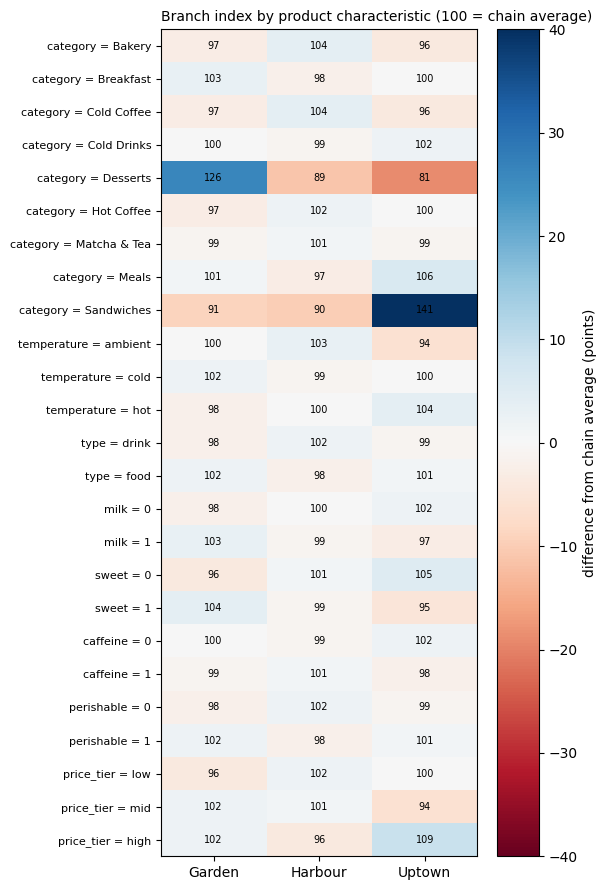

In [100]:
# ===== Characteristic comparison: what sells unusually well or badly at each branch =====
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

units = df.pivot_table(index="Product", columns="Branch", values="Quantity", aggfunc="sum")

# Is the product mix different between branches, beyond chance?
chi2, p, dof, _ = chi2_contingency(units.values)
print(f"Chi-square test of product mix vs branch: chi2={chi2:.0f}, dof={dof}, p={p:.1e}")

# Branch index per product: 100 = sells exactly its chain-wide share; 140 = 40% more than expected
def index_table(units_by_group):
    branch_share = units_by_group / units_by_group.sum()
    chain_share = units_by_group.sum(axis=1) / units_by_group.values.sum()
    return (branch_share.div(chain_share, axis=0) * 100).round(0)

prod_idx = index_table(units).join(tags["category"])
print(prod_idx.sort_values("Uptown", ascending=False).head(6))

# Same index, grouped by each characteristic
rows = []
for col in ["category", "temperature", "type", "milk", "sweet", "caffeine", "perishable", "price_tier"]:
    g = units.join(tags[col]).groupby(col, observed=True).sum()
    idx = index_table(g)
    idx.index = [f"{col} = {v}" for v in idx.index]
    rows.append(idx)
char_idx = pd.concat(rows)
char_idx.to_csv("branch_characteristic_index.csv")

# Heatmap
fig, ax = plt.subplots(figsize=(6, 0.32 * len(char_idx) + 1))
im = ax.imshow(char_idx.values - 100, cmap="RdBu", vmin=-40, vmax=40, aspect="auto")
ax.set_xticks(range(3), char_idx.columns); ax.set_yticks(range(len(char_idx)), char_idx.index, fontsize=8)
for i in range(char_idx.shape[0]):
    for j in range(3):
        ax.text(j, i, f"{char_idx.values[i, j]:.0f}", ha="center", va="center", fontsize=7)
ax.set_title("Branch index by product characteristic (100 = chain average)", fontsize=10, loc="left")
fig.colorbar(im, ax=ax, label="difference from chain average (points)")
plt.tight_layout(); plt.show()

Section A — How product sales mix differs across branches

We compare each product or category’s share of a branch’s total units sold with its share across the chain. An index of 100 means the shares are equal. An index of 140 means the branch’s share is 40% higher, not that it sells 40% more units in absolute terms.

The category comparisons show that desserts have a 26% higher sales share at Garden than across the chain and a 19% lower share at Uptown. Sandwiches have a 41% higher share at Uptown. All four sandwich products have Uptown indices between 134 and 151.

These are differences in recorded sales mix. They do not directly measure customer preferences because availability, stockouts, prices, and promotions may also influence purchases.

Broader characteristics such as temperature, milk, caffeine, and food versus drink show smaller differences, with indices within approximately six points of the chain average.

The chi-square test reports an association between product mix and branch, with a p-value of approximately 5.7 × 10⁻⁴⁸. However, the test treats unit counts as independent, while units bought in the same basket may be related. We therefore emphasize the descriptive sales-share differences rather than treating the p-value as definitive evidence about customer behaviour.

Section C separately evaluates whether characteristics predict total product sales across the chain. On its log-error measure, the characteristics-only neighbour model does not outperform the category baseline, while ridge regression using both characteristics and category performs better overall. The branch comparisons here do not establish why those prediction methods perform differently.

In [101]:
tags

,temperature,type,milk,sweet,caffeine,perishable,price_tier,category
Product,,,,,,,,
Almond Croissant,ambient,food,0,1,0,1,mid,Bakery
Banana Bread,ambient,food,0,1,0,1,mid,Bakery
Blueberry Muffin,ambient,food,0,1,0,1,low,Bakery
Butter Croissant,ambient,food,0,0,0,1,low,Bakery
Chocolate Cookie,ambient,food,0,1,0,1,low,Bakery
Chocolate Croissant,ambient,food,0,1,0,1,low,Bakery
Cinnamon Roll,ambient,food,0,1,0,1,mid,Bakery
Pistachio Cookie,ambient,food,0,1,0,1,low,Bakery
Avocado Toast,hot,food,0,0,0,1,high,Breakfast
